# Business Data Analysis - Lab Midterm Project

## Dataset Used
The Online Retail dataset published by the UCI Machine Learning Repository has been used for this project. This dataset contains all the transactions occurring between December 1, 2010 and December 9, 2011 for a UK-based and registered non-store online retail.

*Note:* The original excel file has been converted to a csv file.

Source: https://archive.ics.uci.edu/dataset/352/online+retail

## Data Understanding & Business Context

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import matplotlib.dates as mdates

sns.set_theme(style="whitegrid")

ModuleNotFoundError: No module named 'plotly'

In [ ]:
# loading and previewing the dataset
df = pd.read_csv("online_retail.csv", parse_dates=["InvoiceDate"])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# printing dataset shape and info
print("Dataset Shape:", df.shape)
print("Dataset Information:")
df.info()
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (541909, 8)
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB

Data Types:
InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [ ]:
# printing summary statistics
print("Summary Statistics:")
display(df.describe(include="all"))

Summary Statistics:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,NaN,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


**Interpretation:**

The dataset contains 541,909 rows and 8 columns, including numerical, categorical, and date/time data. Quantity and UnitPrice are numerical columns, while Country, Description, and StockCode contain categorical information. InvoiceDate has been loaded as a datetime column.

The dataset contains 25,900 unique invoice numbers, 4,070 unique stock codes, and records from 38 countries. The United Kingdom has the highest number of records (495,478).

There are missing values in Description and CustomerID. The summary statistics also show negative and unusually large values in Quantity and UnitPrice, which will be investigated during data cleaning.

**Business Context:**

The Online Retail dataset contains transactions from a UK-based online retail business. According to the UCI source, the company mainly sells unique all-occasion gifts, and many of its customers are wholesalers. The dataset covers transactions from December 1, 2010, to December 9, 2011. 

Each row represents a product entry within an invoice, including its quantity and unit price. An invoice can contain multiple product entries, as shown by repeated invoice numbers in the dataset preview. The dataset also includes product descriptions, customer IDs, transaction dates, and countries. This data can be used to analyze sales trends, product performance, customer purchasing patterns, and transaction cancellations.

**Business Questions:**

1. How do sales and revenue change over time?

2. Which products and countries contribute the most to sales revenue?

3. How do product prices and purchase quantities relate to transaction revenue?

4. How do cancellations affect sales performance?

## Data Cleaning & Preparation

In [ ]:
# checking for missing values and duplicate rows
print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# checking for invalid/unusual values
print("Negative Quantities:", (df["Quantity"] < 0).sum())
print("Zero Quantities:", (df["Quantity"] == 0).sum())
print("Negative Prices:", (df["UnitPrice"] < 0).sum())
print("Zero Prices:", (df["UnitPrice"] == 0).sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268
Negative Quantities: 10624
Zero Quantities: 0
Negative Prices: 2
Zero Prices: 2515


In [ ]:
# removing rows with missing descriptions
df = df.dropna(subset=["Description"])

# checking remaining missing values
print(df.isnull().sum())

# rows with missing CustomerID are kept for the overall sales analysis

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133626
Country             0
dtype: int64


In [ ]:
# removing exact duplicate rows
df = df.drop_duplicates()
print("Remaining Rows:", len(df))
print("Duplicate Rows:", df.duplicated().sum())

Remaining Rows: 535187
Duplicate Rows: 0


In [ ]:
# removing rows with zero or negative unit prices
df = df[df["UnitPrice"] > 0]

# checking remaining values
print("Negative Prices:", (df["UnitPrice"] < 0).sum())
print("Zero Prices:", (df["UnitPrice"] == 0).sum())
print("Negative Quantities:", (df["Quantity"] < 0).sum())

Negative Prices: 0
Zero Prices: 0
Negative Quantities: 9251


In [ ]:
# ensuring InvoiceDate is in datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print(df.dtypes)

# checking for errors
print("Missing Dates:", df["InvoiceDate"].isna().sum())

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object
Missing Dates: 0


In [ ]:
# checking stock codes that do not start with five digits
print("Records to remove:", (~df["StockCode"].str.match(r"^\d{5}")).sum())

# keeping stock codes that start with five digits
df = df[df["StockCode"].str.match(r"^\d{5}")]

print("Remaining Rows:", len(df))

Records to remove: 2957
Remaining Rows: 531172


In [ ]:
# checking records with extremely large quantities
print("Records to remove:", (df["Quantity"].abs() >= 70000).sum())

# removing records with extremely large quantities
df = df[df["Quantity"].abs() < 70000]

print("Remaining Rows:", len(df))

Records to remove: 4
Remaining Rows: 531168


In [ ]:
# extracting time-based features from date column
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
df["Weekday"] = df["InvoiceDate"].dt.day_name()

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,Weekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday


In [ ]:
# final checks
print("Final Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Nonpositive Prices:", (df["UnitPrice"] <= 0).sum())
print("\nData Types:")
print(df.dtypes)
df.head()

Final Shape: (531168, 10)
Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131516
Country             0
YearMonth           0
Weekday             0
dtype: int64
Duplicate Rows: 0
Nonpositive Prices: 0

Data Types:
InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
YearMonth      datetime64[us]
Weekday                   str
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,Weekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday


In [ ]:
# building the cleaning log
cleaning_log = pd.DataFrame({
    "Problem Found": [
        "Missing descriptions",
        "Missing customer IDs",
        "Duplicate rows",
        "Zero and negative unit prices",
        "Non-standard stock code formats",
        "Extremely large quantities",
        "Negative quantities",
        "Date and time preparation"
    ],
    "Action Taken": [
        "Removed rows with missing descriptions",
        "Kept missing values",
        "Removed exact duplicates",
        "Removed rows with nonpositive prices",
        "Kept stock codes starting with five digits",
        "Removed rows with absolute quantity of 70,000 or more",
        "Kept the remaining negative quantities",
        "Checked InvoiceDate and extracted YearMonth and Weekday"
    ],
    "Reason": [
        "Descriptions are needed for product analysis",
        "Customer IDs are not required for overall sales analysis",
        "To avoid possible double-counting",
        "To focus on entries with positive unit prices",
        "To focus the analysis on standard product stock codes",
        "To prevent extreme quantities from dominating the analysis",
        "They may represent cancellations or returns",
        "To support analysis of sales over time"
    ]
})
pd.set_option("display.max_colwidth", None)
cleaning_log

,Problem Found,Action Taken,Reason
0,Missing descriptions,Removed rows with missing descriptions,Descriptions are needed for product analysis
1,Missing customer IDs,Kept missing values,Customer IDs are not required for overall sales analysis
2,Duplicate rows,Removed exact duplicates,To avoid possible double-counting
3,Zero and negative unit prices,Removed rows with nonpositive prices,To focus on entries with positive unit prices
4,Non-standard stock code formats,Kept stock codes starting with five digits,To focus the analysis on standard product stock codes
5,Extremely large quantities,"Removed rows with absolute quantity of 70,000 or more",To prevent extreme quantities from dominating the analysis
6,Negative quantities,Kept the remaining negative quantities,They may represent cancellations or returns
7,Date and time preparation,Checked InvoiceDate and extracted YearMonth and Weekday,To support analysis of sales over time


## Feature Engineering

In [ ]:
# creating Revenue column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [ ]:
# creating column to identify cancellation records
df["IsCancellation"] = df["InvoiceNo"].str.startswith("C")
print(df["IsCancellation"].value_counts())
df[["InvoiceNo", "Quantity", "IsCancellation"]].head()

IsCancellation
False    522502
True       8666
Name: count, dtype: int64


,InvoiceNo,Quantity,IsCancellation
0,536365,6,False
1,536365,6,False
2,536365,8,False
3,536365,6,False
4,536365,6,False


In [ ]:
# creating column to group products into price categories (low, medium, high)
df["PriceCategory"] = pd.cut(df["UnitPrice"], bins=[0, 5, 20, float("inf")], labels=["Low", "Medium", "High"])
print(df["PriceCategory"].value_counts())
df[["UnitPrice", "PriceCategory"]].head(10)

PriceCategory
Low       446192
Medium     82318
High        2658
Name: count, dtype: int64


,UnitPrice,PriceCategory
0,2.55,Low
1,3.39,Low
2,2.75,Low
3,3.39,Low
4,3.39,Low
5,7.65,Medium
6,4.25,Low
7,1.85,Low
8,1.85,Low
9,1.69,Low


In [ ]:
# final check
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (531168, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,Weekday,Revenue,IsCancellation,PriceCategory
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,Wednesday,15.30,False,Low
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday,20.34,False,Low
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,Wednesday,22.00,False,Low
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday,20.34,False,Low
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,Wednesday,20.34,False,Low


**Interpretation:**

Three new columns were created in addition to the two columns (YearMonth, Weekday) extracted from InvoiceDate.
- Revenue was calculated by multiplying Quantity and UnitPrice, allowing us to measure the value of each transaction entry.
- IsCancellation was created to identify invoices marked as cancellations.
- PriceCategory was created to group product entries into low, medium, and high price ranges.

These features will help analyze revenue trends, product performance, pricing patterns, and cancellations.

Revenue is calculated as Quantity × UnitPrice. Since negative quantities are retained, the sum of Revenue includes both positive and negative recorded transaction values.

## EDA & Visualization

### Business Question 1: How do sales and revenue change over time?

#### Chart 1: Monthly Net Recorded Revenue

In [ ]:
# calculating monthly revenue
monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()
print(monthly_revenue)

print("\nHighest revenue month:", monthly_revenue.idxmax().strftime("%B %Y"))
print(f"Highest monthly revenue: £{monthly_revenue.max():,.2f}")

YearMonth
2010-12-01     758024.37
2011-01-01     578836.94
2011-02-01     499447.90
2011-03-01     679204.19
2011-04-01     482038.72
2011-05-01     730966.12
2011-06-01     723845.14
2011-07-01     676737.53
2011-08-01     701270.19
2011-09-01    1011333.16
2011-10-01    1061697.93
2011-11-01    1427121.25
2011-12-01     440396.27
Name: Revenue, dtype: float64

Highest revenue month: November 2011
Highest monthly revenue: £1,427,121.25


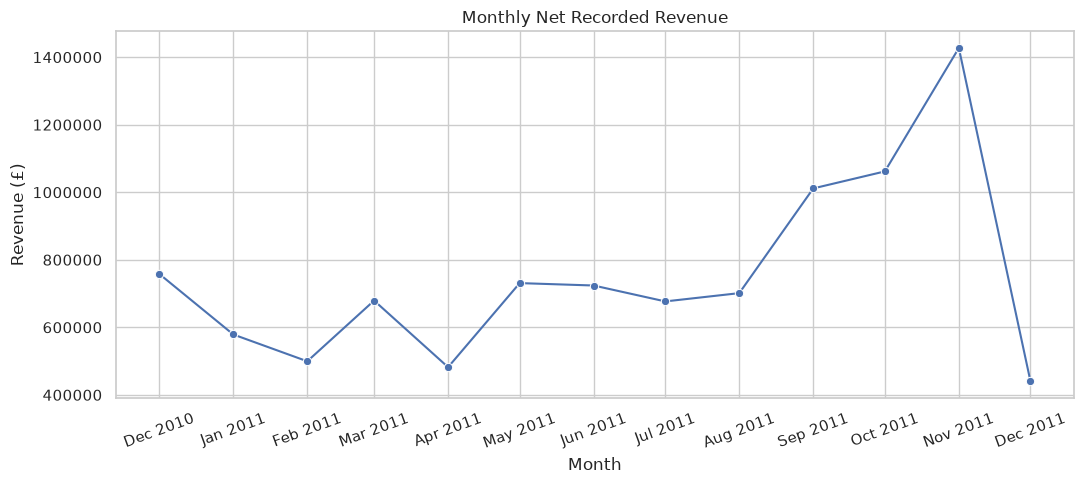

In [ ]:
# plotting the line chart
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(x=monthly_revenue.index, y=monthly_revenue.values, marker="o", ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=20)
ax.ticklabel_format(style="plain", axis="y")
ax.set(title="Monthly Net Recorded Revenue", xlabel="Month", ylabel="Revenue (£)")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** Monthly revenue changes throughout the dataset period, with November 2011 recording the highest revenue of approximately £1.43 million.

**So what?** Revenue varies across months, which suggests that sales activity is not constant throughout the year. December 2011 contains only part of the month, so its revenue cannot be compared directly with complete months.

**Now what?** The business could investigate the reasons for higher revenue in certain months and use these findings for inventory and sales planning.

#### Chart 2: Net Recorded Revenue by Weekday

In [ ]:
# calculating revenue by weekday
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
weekday_revenue = df.groupby("Weekday")["Revenue"].sum().reindex(days)
print(weekday_revenue.sort_values(ascending=False))

Weekday
Thursday     2080448.85
Tuesday      1967975.35
Wednesday    1738728.78
Monday       1622110.41
Friday       1570856.43
Sunday        790799.89
Name: Revenue, dtype: float64


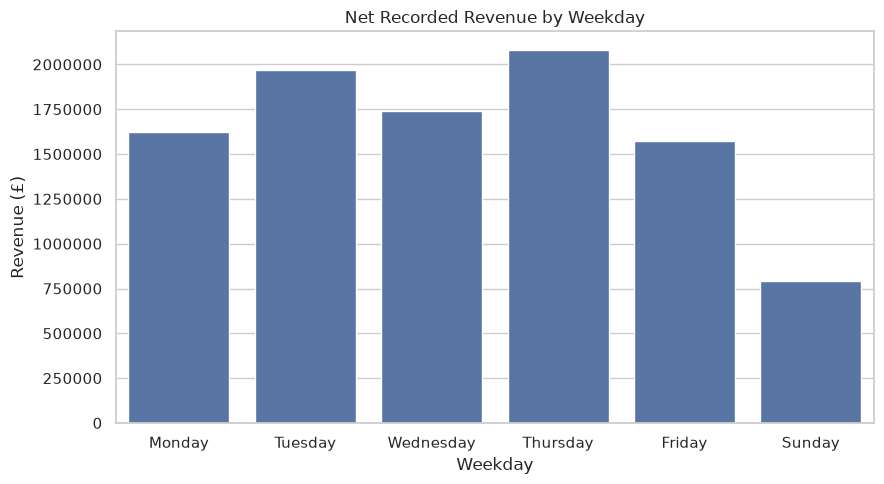

In [ ]:
# plotting the bar chart
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=weekday_revenue.index, y=weekday_revenue.values, ax=ax)
ax.set(title="Net Recorded Revenue by Weekday", xlabel="Weekday", ylabel="Revenue (£)")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** Thursday has the highest recorded revenue at approximately £2.08 million, followed by Tuesday at £1.97 million. Sunday has the lowest total at approximately £790,800.

**So what?** Recorded revenue differs across weekdays, with Thursday and Tuesday contributing relatively more during the dataset period.

**Now what?** The business could examine daily sales patterns and use them when planning staffing and promotional activities.

#### Chart 3: Monthly Number of Unique Invoices

In [ ]:
# calculating the number of unique invoices by month
monthly_invoices = df.groupby("YearMonth")["InvoiceNo"].nunique()
print(monthly_invoices.sort_values(ascending=False))

print("\nHighest invoice month:", monthly_invoices.idxmax().strftime("%B %Y"))
print("Highest invoice count:", monthly_invoices.max())
print("Lowest full-month invoice count:", monthly_invoices.iloc[1:-1].min())

YearMonth
2011-11-01    3147
2011-10-01    2313
2011-09-01    2117
2011-05-01    1935
2010-12-01    1851
2011-06-01    1824
2011-03-01    1721
2011-07-01    1688
2011-08-01    1579
2011-04-01    1455
2011-01-01    1326
2011-02-01    1284
2011-12-01     951
Name: InvoiceNo, dtype: int64

Highest invoice month: November 2011
Highest invoice count: 3147
Lowest full-month invoice count: 1284


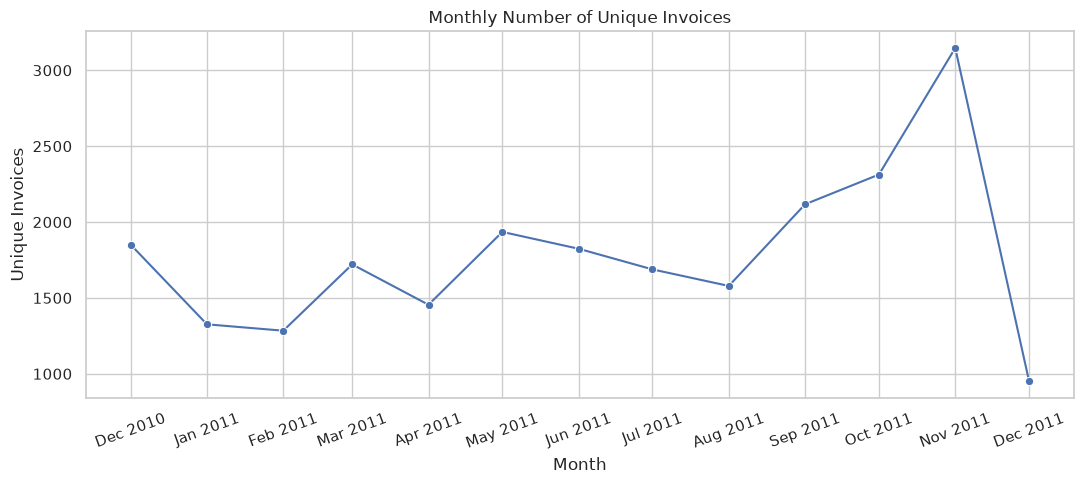

In [ ]:
# plotting the line chart
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(x=monthly_invoices.index, y=monthly_invoices.values, marker="o", ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=20)
ax.set(title="Monthly Number of Unique Invoices", xlabel="Month", ylabel="Unique Invoices")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** November 2011 recorded the highest number of unique invoices (3,147), followed by October (2,313) and September (2,117). February 2011 had the lowest count among complete months, with 1,284 invoices.

**So what?** Invoice activity increased during the later months of 2011, particularly from September to November. November also had the highest monthly revenue, suggesting that greater invoice activity contributed to its stronger revenue performance.

**Now what?** The business could investigate whether this pattern repeats in other years and plan inventory and operations for periods of higher demand.

### Business Question 2: Which products and countries contribute the most revenue?

#### Chart 4: Top 10 Descriptions by Net Recorded Revenue

In [ ]:
# finding the 10 descriptions with the highest revenue
top_products = (df.groupby("Description")["Revenue"].sum().nlargest(10))
print(top_products)

Description
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
Name: Revenue, dtype: float64


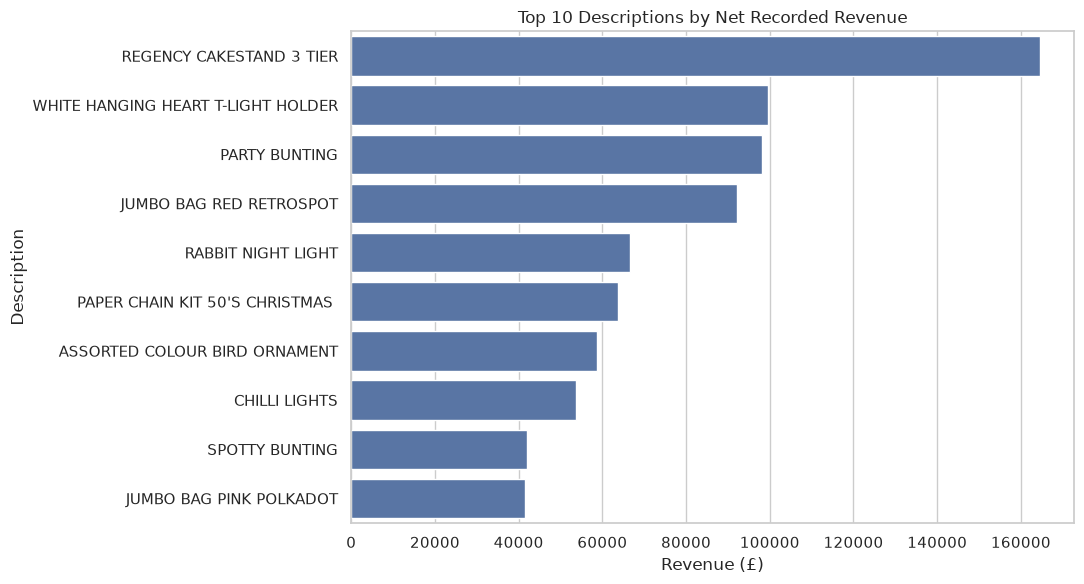

In [ ]:
# plotting the horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=top_products.values, y=top_products.index, ax=ax)
ax.set(title="Top 10 Descriptions by Net Recorded Revenue", xlabel="Revenue (£)", ylabel="Description")
ax.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** REGENCY CAKESTAND 3 TIER has the highest recorded revenue at £164,459, followed by WHITE HANGING HEART T-LIGHT HOLDER at £99,612 and PARTY BUNTING at £98,244.

**So what?** Some product descriptions contribute considerably more revenue than others.

**Now what?** The business could prioritize high-revenue products when reviewing stock levels and product availability.

#### Chart 5: Top 10 Non-UK Countries by Net Recorded Revenue

In [ ]:
# finding the 10 non-UK countries with the highest revenue
top_countries = (df[df["Country"] != "United Kingdom"].groupby("Country")["Revenue"].sum().nlargest(10))
print(top_countries)

# calculating the UK's share of total revenue
uk_share = df.loc[df["Country"] == "United Kingdom", "Revenue"].sum() / df["Revenue"].sum() * 100
print(f"UK share of revenue: {uk_share:.1f}%")

Country
Netherlands    283479.54
EIRE           259380.02
Germany        200619.66
France         182076.60
Australia      136922.50
Switzerland     52483.05
Spain           51746.65
Belgium         36662.96
Japan           35419.79
Sweden          35166.41
Name: Revenue, dtype: float64
UK share of revenue: 84.8%


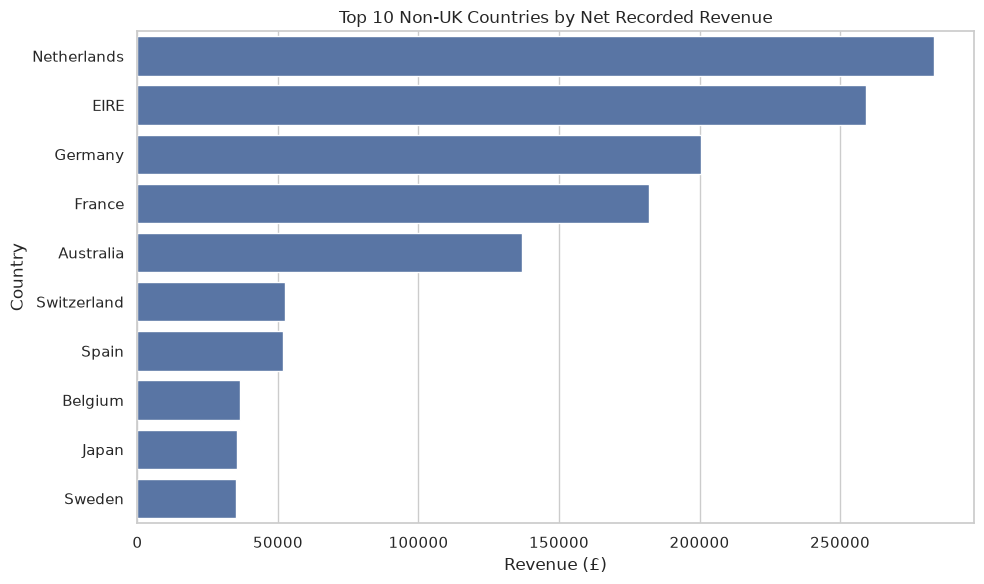

In [ ]:
# plotting the bar chart
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, ax=ax)
ax.set(title="Top 10 Non-UK Countries by Net Recorded Revenue", xlabel="Revenue (£)", ylabel="Country")
ax.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** The United Kingdom contributes approximately 84.8% of total recorded revenue. Among countries outside the UK, the Netherlands has the highest revenue at approximately £283,480, followed by EIRE at £259,380 and Germany at £200,620.

**So what?** The business depends heavily on its UK market, while other countries contribute smaller shares of revenue. 

**Now what?** The business could investigate opportunities to strengthen sales in its existing international markets.

#### Chart 6: Net Recorded Revenue by Price Category

In [ ]:
# calculating revenue by price category
price_revenue = df.groupby("PriceCategory", observed=True)["Revenue"].sum()
print(price_revenue)

PriceCategory
Low       7480188.94
Medium    2108508.58
High       182222.19
Name: Revenue, dtype: float64


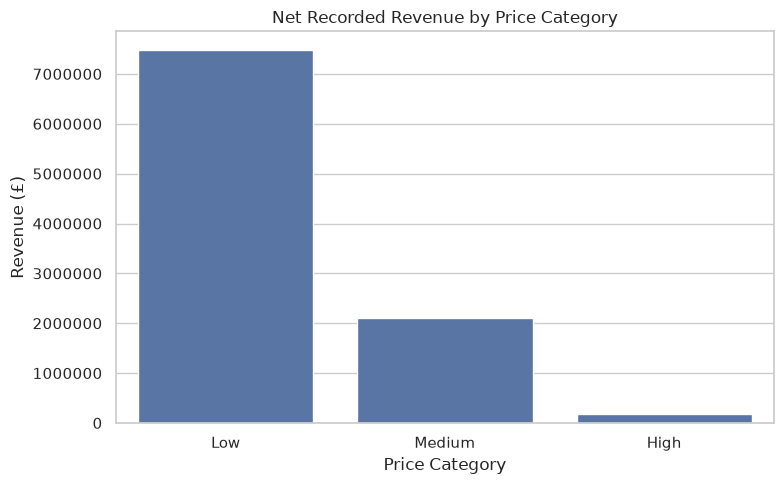

In [ ]:
# plotting the bar chart
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=price_revenue.index, y=price_revenue.values, ax=ax)
ax.set(title="Net Recorded Revenue by Price Category", xlabel="Price Category", ylabel="Revenue (£)")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** The Low price category contributes approximately £7.48 million in revenue, compared with £2.11 million from Medium and £182,222 from High.

**So what?** Most recorded revenue comes from entries with unit prices of £5 or below.

**Now what?** The business could consider this purchasing pattern when planning its product range and inventory.

### Business Question 3: How do prices and quantities relate to revenue?

#### Chart 7: Distribution of Unit Prices (£0–£10)

In [ ]:
# checking the distribution of unit prices
print("Entries priced £3 or below:", (df["UnitPrice"] <= 3).sum())
print("Entries priced £10 or below:", (df["UnitPrice"] <= 10).sum())
print("Entries priced above £10:", (df["UnitPrice"] > 10).sum())

Entries priced £3 or below: 351119
Entries priced £10 or below: 508703
Entries priced above £10: 22465


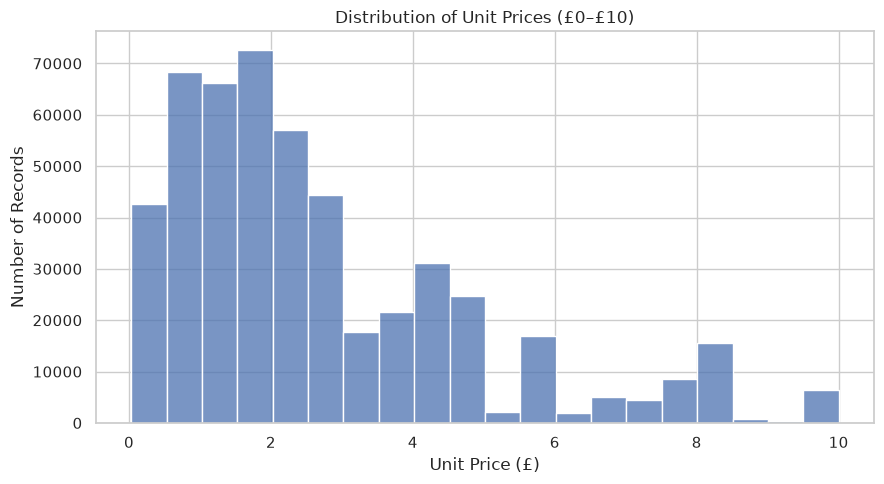

In [ ]:
# plotting a histogram to check the distribution of unit prices
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df.loc[df["UnitPrice"] <= 10, "UnitPrice"], binwidth=0.5, ax=ax)
ax.set(title="Distribution of Unit Prices (£0–£10)", xlabel="Unit Price (£)", ylabel="Number of Records")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** The histogram shows that unit prices are concentrated toward the lower end of the £0–£10 range. A total of 351,119 records have unit prices of £3 or below, while 22,465 records are priced above £10 and are excluded from the chart.

**So what?**  Lower-priced entries appear much more frequently in the dataset than higher-priced entries. This is consistent with the Low price category contributing the largest share of recorded revenue.

**Now what?** The business could review its most frequently sold price ranges when planning product offerings and inventory.

#### Chart 8: Unit Price vs Quantity (Selected Range)

In [ ]:
# checking the number of records within the selected range
print("Plotted records:", len(df[
    (df["UnitPrice"] <= 50) &
    (df["Quantity"] > 0) &
    (df["Quantity"] <= 100)
]))

Plotted records: 517440


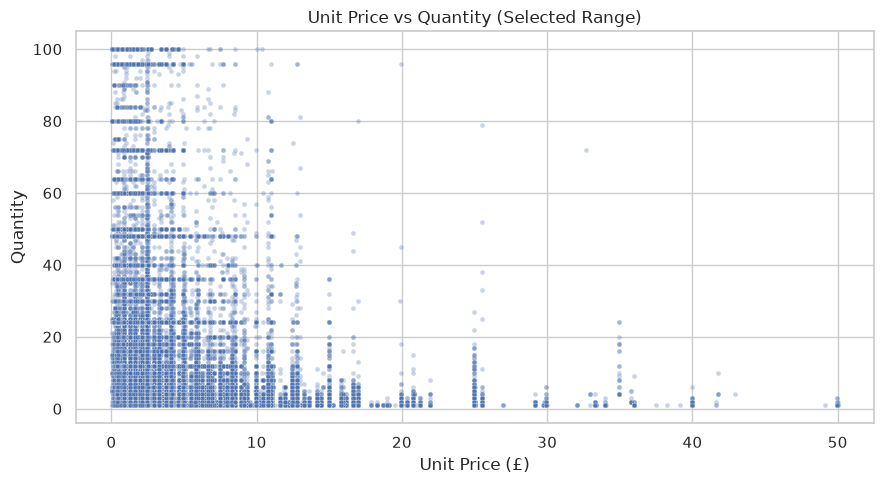

In [ ]:
# plotting a scatterplot to check the relationship between UnitPrice and Quantity
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=df[
        (df["UnitPrice"] <= 50) &
        (df["Quantity"] > 0) &
        (df["Quantity"] <= 100)
    ], x="UnitPrice", y="Quantity", alpha=0.3, s=12, ax=ax)
ax.set(title="Unit Price vs Quantity (Selected Range)", xlabel="Unit Price (£)", ylabel="Quantity")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** The scatter plot displays 517,440 records with positive quantities of 100 or below and unit prices of £50 or below. It shows that many observations are concentrated at relatively low prices and quantities, with some larger quantities occurring across the displayed price range.

**So what?** Purchasing quantities vary across different unit prices. However, the plot does not establish a strong relationship between price and quantity, and the selected ranges exclude extreme observations.

**Now what?** The business could examine purchasing quantities within different price ranges to better understand customer purchasing patterns.

#### Chart 9: Correlation Between Quantity, Unit Price and Revenue

In [ ]:
# calculating correlations between numerical variables
corr = df[["Quantity", "UnitPrice", "Revenue"]].corr()
print(corr)

           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.078434  0.503330
UnitPrice -0.078434   1.000000  0.180141
Revenue    0.503330   0.180141  1.000000


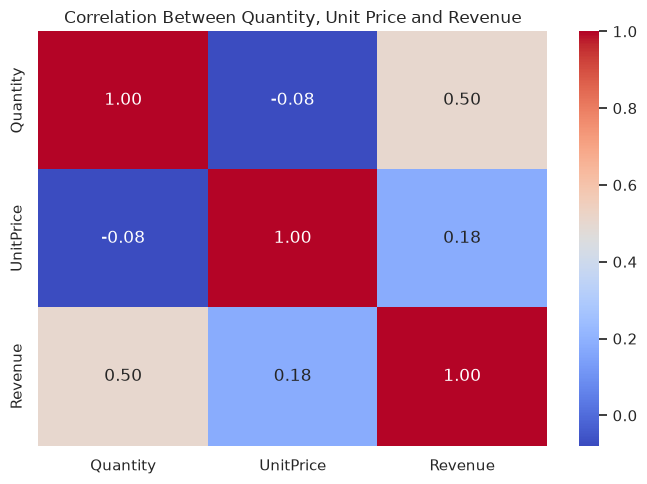

In [ ]:
# plotting the correlation heatmap
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Correlation Between Quantity, Unit Price and Revenue")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** Quantity and Revenue have a moderate positive correlation of approximately 0.50. UnitPrice and Revenue have a weak positive correlation of 0.18, while Quantity and UnitPrice have a very weak negative correlation of -0.08.

**So what?** Quantity has a stronger linear relationship with Revenue than UnitPrice does in this dataset. However, Revenue is calculated using both variables, so these relationships are partly mathematical.

**Now what?** The business could further investigate quantity and pricing patterns to understand their contributions to recorded revenue.

### Business Question 4: How do cancellations affect sales performance?

#### Chart 10: Average Absolute Line Value by Price Category and Cancellation Status

In [ ]:
# calculating average absolute line value by price category and cancellation status
avg_line_value = (df.groupby(["PriceCategory", "IsCancellation"], observed=True)["Revenue"].agg(lambda x: x.abs().mean()).reset_index(name="AverageLineValue"))
print(avg_line_value.round(2))

  PriceCategory  IsCancellation  AverageLineValue
0           Low           False             17.38
1           Low            True             23.54
2        Medium           False             26.99
3        Medium            True             34.45
4          High           False             73.67
5          High            True            102.94


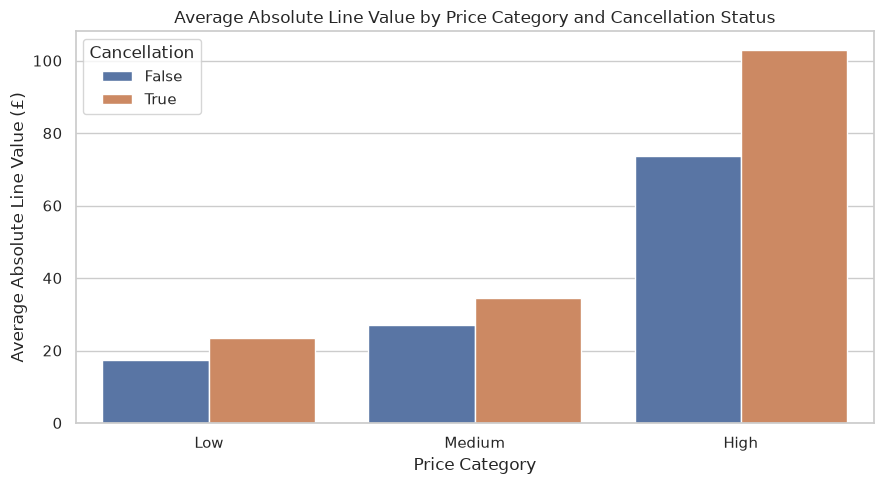

In [ ]:
# plotting the grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=avg_line_value, x="PriceCategory", y="AverageLineValue", hue="IsCancellation", errorbar=None, ax=ax)
ax.set(title="Average Absolute Line Value by Price Category and Cancellation Status", xlabel="Price Category", ylabel="Average Absolute Line Value (£)")
ax.legend(title="Cancellation")
plt.tight_layout()
plt.show()

**Interpretation:**

**What?** The average absolute line value is higher for cancellation entries in all three price categories. In the Low category, the averages are £23.54 for cancellations and £17.38 for non-cancellations. In Medium, they are £34.45 and £26.99, while in High, they are £102.94 and £73.67.

**So what?** Cancellation entries have higher average monetary values than non-cancellation entries within each price category. This suggests that cancellations may involve relatively larger transaction entries, even though cancellation records are less frequent.

**Now what?** The business could monitor the value and frequency of cancellation entries, especially in the High price category, and investigate the reasons behind them.

#### Chart 11: Interactive Monthly Net Recorded Revenue

In [ ]:
# displaying monthly revenue for the interactive chart
print(monthly_revenue)

YearMonth
2010-12-01     758024.37
2011-01-01     578836.94
2011-02-01     499447.90
2011-03-01     679204.19
2011-04-01     482038.72
2011-05-01     730966.12
2011-06-01     723845.14
2011-07-01     676737.53
2011-08-01     701270.19
2011-09-01    1011333.16
2011-10-01    1061697.93
2011-11-01    1427121.25
2011-12-01     440396.27
Name: Revenue, dtype: float64


In [ ]:
# plotting the interactive monthly revenue chart
fig = px.line(x=monthly_revenue.index, y=monthly_revenue.values, markers=True, title="Interactive Monthly Net Recorded Revenue",
            labels={"x": "Month", "y": "Revenue (£)"})
fig.update_layout(hovermode="x unified")
fig.update_xaxes(tickformat="%b %Y", dtick="M1")
fig.show()

**Interpretation:**

**What?** The interactive chart displays monthly recorded revenue, with exact values available when hovering over the points. November 2011 has the highest recorded revenue.

**So what?** The interactive chart makes it easier to compare individual months and identify changes in revenue over time.

**Now what?** The business could investigate months with unusually high or low revenue and use these findings for future planning.

#### Chart 12: Cancellation vs Non-Cancellation Records

In [ ]:
# counting cancellation and non-cancellation records
cancellation_counts = (df["IsCancellation"].value_counts().rename_axis("IsCancellation").reset_index(name="Records"))

# adding labels for the chart
cancellation_counts["Status"] = cancellation_counts["IsCancellation"].map({
    False: "Not marked as cancellation",
    True: "Cancellation"
})
print(cancellation_counts[["Status", "Records"]])

                       Status  Records
0  Not marked as cancellation   522502
1                Cancellation     8666


In [ ]:
# plotting the interactive cancellation chart
fig = px.bar(cancellation_counts, x="Status", y="Records", color="Status", text="Records", title="Cancellation vs Non-Cancellation Records", 
    labels={"Status": "Invoice Status", "Records": "Number of Records"})
fig.update_traces(textposition="outside")
fig.update_layout(showlegend=False)
fig.update_yaxes(range=[0, cancellation_counts["Records"].max() * 1.15])
fig.show()

**Interpretation:**

**What?** The dataset contains 8,666 records marked as cancellations and 522,502 records not marked as cancellations.

**So what?** Cancellation entries represent a relatively small proportion of the recorded line items, although their monetary values may still be important.

**Now what?** The business could investigate cancellation patterns and possible reasons for cancelled transactions.

## Insights, Recommendations & Executive Summary

### Key Numerical Insights

1. **Total recorded revenue:** The cleaned dataset contains approximately £9.77 million in net recorded revenue.

2. **Highest revenue month:** November 2011 recorded the highest monthly revenue at £1,427,121.25.

3. **Highest revenue weekday:** Thursday contributed £2,080,448.85, the highest total among weekdays.

4. **UK market contribution:** The United Kingdom accounted for approximately 84.8% of recorded revenue.

5. **Leading international markets:** The Netherlands (£283,479.54), EIRE (£259,380.02), and Germany (£200,619.66) were the top three non-UK markets by revenue.

6. **Highest-revenue product description:** REGENCY CAKESTAND 3 TIER generated £164,459.49, the highest revenue among product descriptions.

7. **Price-category performance:** Low-priced entries contributed £7,480,188.94, considerably more than Medium (£2,108,508.58) and High (£182,222.19).

8. **Cancellation records:** Of the 531,168 remaining records, 8,666 (approximately 1.63%) were marked as cancellations.

### Business Recommendations

1. **Improve inventory planning:** The business should monitor demand for its highest-revenue products, such as REGENCY CAKESTAND 3 TIER, to reduce the risk of stock shortages.

2. **Plan for changes in monthly demand:** Since November 2011 recorded the highest revenue, the business could investigate whether similar patterns occur in other years and prepare inventory accordingly.

3. **Explore international market opportunities:** As approximately 84.8% of revenue comes from the UK, the business could investigate opportunities to expand sales in existing international markets, particularly the Netherlands, EIRE, and Germany.

4. **Monitor cancellations:** The business should track cancellation frequency and monetary values to identify patterns and investigate possible causes. This could help reduce unnecessary cancellations and improve sales performance.

### Executive Summary

This project analyzes the Online Retail dataset from the UCI Machine Learning Repository, covering transactions from December 2010 to December 2011. The purpose of the analysis was to understand revenue trends, product performance, purchasing patterns, and cancellations.

After data cleaning, 531,168 records remained. The dataset was analyzed using numerical summaries, static visualizations, and interactive charts.

The findings show that recorded revenue was approximately £9.77 million, with November 2011 having the highest monthly revenue of £1.43 million. The United Kingdom contributed approximately 84.8% of total revenue, showing that it was the company's main market. Among other countries, the Netherlands, EIRE, and Germany contributed the highest revenues.

REGENCY CAKESTAND 3 TIER was the highest-revenue product description, while the Low price category contributed the largest share of revenue. The analysis also identified 8,666 cancellation records.

Based on these findings, the business should focus on inventory planning, investigate monthly sales patterns, explore international markets, and monitor cancellations. These actions could help improve business decisions and sales performance.

### Limitations

The dataset covers approximately one year, so the findings may not represent longer-term trends. Some records were excluded during cleaning, including entries with non-standard stock code formats and extremely large quantities, which may affect the results. Revenue was calculated using Quantity and UnitPrice and does not represent profit. Cancellation values also do not necessarily represent actual financial losses. Additionally, the first and last months of the dataset are incomplete, so their revenue totals should be compared with other months carefully.